Nama    : Candra Sya'bana Putra Gunadi <br>
NIM     : 60324042 <br>
Kelas   : Visualisasi Data (A) <br>

# Praktikum

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(url)
df["age"] = df["age"].fillna(df["age"].mean())
df = df.dropna(subset=["embarked"])
df = df.drop_duplicates()
print("Data siap divisualisasikan:", df.shape)

Data siap divisualisasikan: (782, 15)


Membuat Grafik Berkelompok (Grouped Bar) dengan Legenda

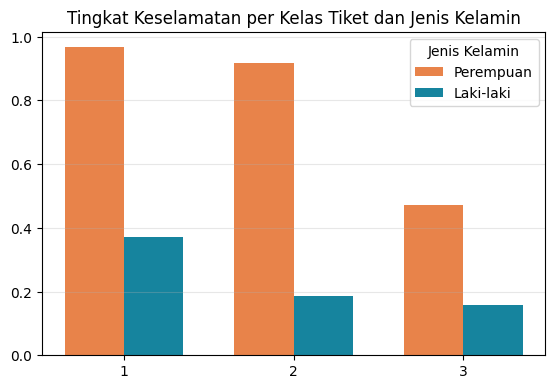

In [2]:
pt = df.pivot_table(values="survived",
                index="pclass", columns="sex",
                aggfunc="mean")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
x = np.arange(len(pt.index))
width = 0.35

ax.bar(x - width/2, pt["female"], width,
    label="Perempuan", color="#E8834A")
ax.bar(x + width/2, pt["male"], width,
    label="Laki-laki", color="#16849E")

ax.set_title("Tingkat Keselamatan per Kelas Tiket dan Jenis Kelamin")
ax.set_xticks(x); ax.set_xticklabels(pt.index)
ax.legend(title="Jenis Kelamin")
ax.grid(axis="y", alpha=0.3)
plt.show()

Menata Grid dan Sumbu

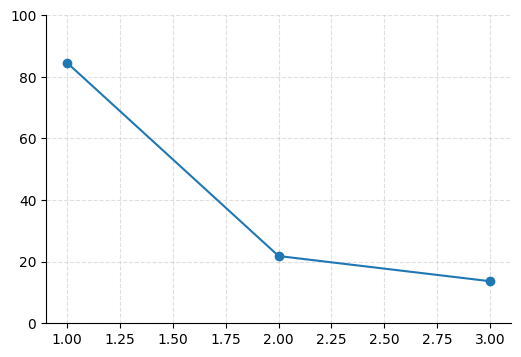

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
rata_fare = df.groupby("pclass")["fare"].mean()
ax.plot(rata_fare.index, rata_fare.values, marker="o")
ax.grid(True, linestyle="--", alpha=0.4)
ax.set_ylim(0, 100)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

Membuat Grid Subplot 2x2

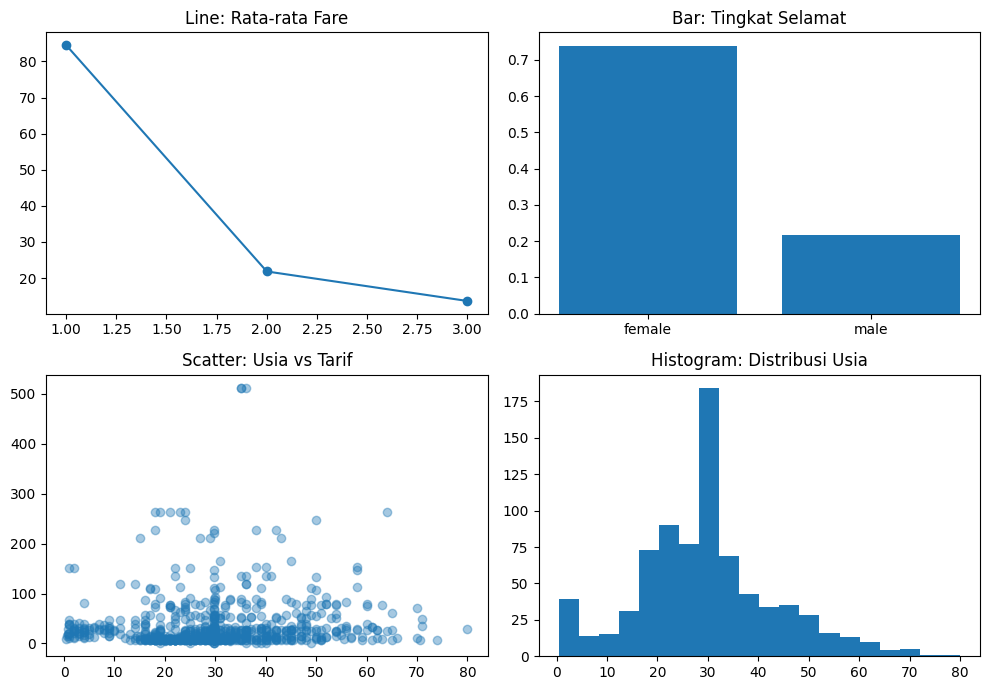

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
tingkat = df.groupby("sex")["survived"].mean()

axes[0,0].plot(rata_fare.index, rata_fare.values, marker="o")
axes[0,0].set_title("Line: Rata-rata Fare")

axes[0,1].bar(tingkat.index, tingkat.values)
axes[0,1].set_title("Bar: Tingkat Selamat")

axes[1,0].scatter(df["age"], df["fare"], alpha=0.4)
axes[1,0].set_title("Scatter: Usia vs Tarif")

axes[1,1].hist(df["age"], bins=20)
axes[1,1].set_title("Histogram: Distribusi Usia")

plt.tight_layout(); plt.show()

Menggunakan Palet Warna Kustom

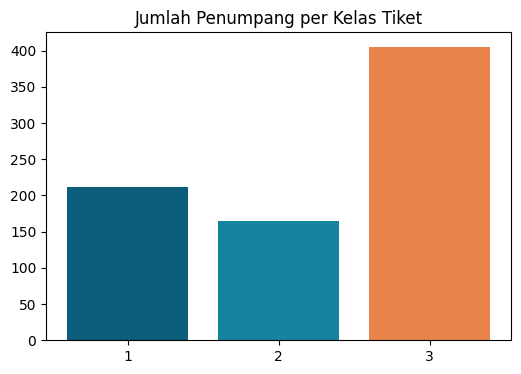

In [5]:
# Palet warna kustom bergaya course branding
palet = ["#0B5D7A", "#16849E", "#E8834A"]

jumlah_kelas = df["pclass"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(jumlah_kelas.index.astype(str), jumlah_kelas.values, color=palet)
ax.set_title("Jumlah Penumpang per Kelas Tiket")
plt.show()

Menggunakan Gaya (Style) Matplotlib

['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


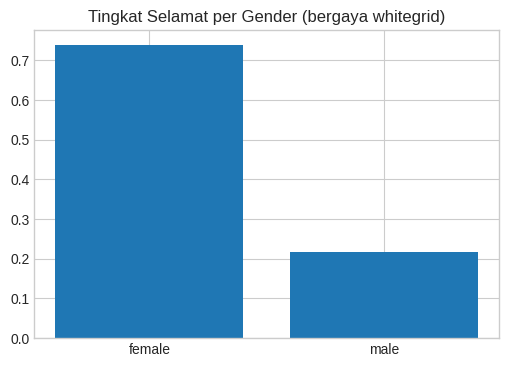

In [6]:
print(plt.style.available) # lihat daftar gaya tersedia

plt.style.use("seaborn-v0_8-whitegrid")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(tingkat.index, tingkat.values)
ax.set_title("Tingkat Selamat per Gender (bergaya whitegrid)")
plt.show()

Menyempurnakan Grafik dari Pertemuan 5

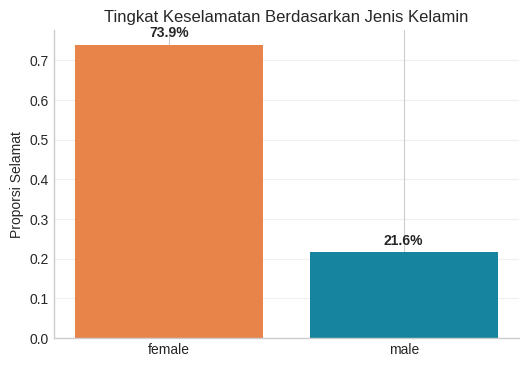

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(tingkat.index, tingkat.values,
        color=["#E8834A", "#16849E"])

for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02,
        f"{bar.get_height():.1%}", ha="center", fontweight="bold")

ax.set_title("Tingkat Keselamatan Berdasarkan Jenis Kelamin")
ax.set_ylabel("Proporsi Selamat")
ax.grid(axis="y", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

Sesi Peer Review

Lembar Peer Review <br>

Direview oleh: [Inggil Himawan]
1. Apakah setiap grafik memiliki judul yang jelas? (Ya)
2. Apakah label sumbu X dan Y sudah ada dan informatif? (Ya)
3. Apakah grafik dengan beberapa kategori memiliki legenda? (Ya)
4. Apakah pemilihan warna cukup kontras dan mudah dibedakan? (Ya)
5. Satu hal yang paling baik dari grafik ini: Notebook sudah baik dari segi pemanggilan library, struktur kode dan hasil running tiap cell

# Latihan Mandiri

Latihan 1

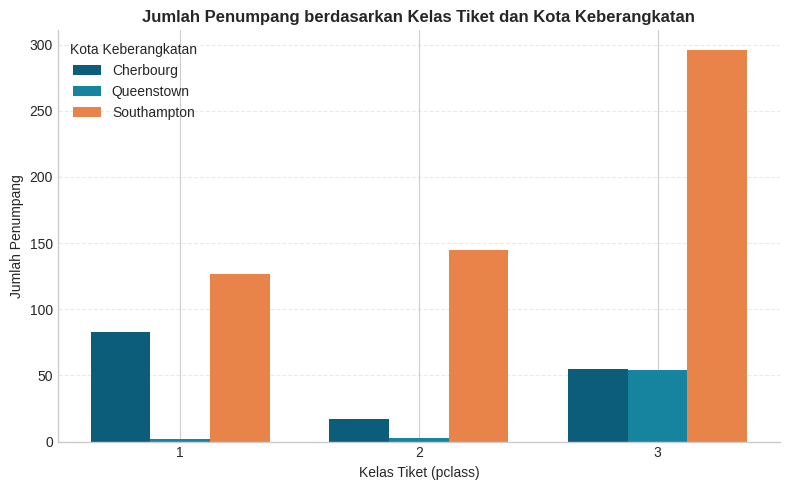

In [8]:
# Memuat data Titanic
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df_clean = pd.read_csv(url)
df_clean["age"] = df_clean["age"].fillna(df_clean["age"].mean())
df_clean = df_clean.dropna(subset=["embarked"])
df_clean = df_clean.drop_duplicates()

# Membuat pivot table jumlah penumpang
pt_counts = df_clean.pivot_table(values="survived",
                                 index="pclass",
                                 columns="embark_town",
                                 aggfunc="count")

# Menentukan ukuran figure
fig, ax = plt.subplots(figsize=(8, 5))

# Menentukan posisi x dan lebar bar
x = np.arange(len(pt_counts.index))
width = 0.25

# Menentukan warna kustom sesuai estetika
colors = ["#0B5D7A", "#16849E", "#E8834A"]

# Membuat bar untuk setiap kota keberangkatan (embark_town)
for i, col in enumerate(pt_counts.columns):
    ax.bar(x + (i - 1) * width, pt_counts[col], width,
           label=col, color=colors[i % len(colors)])

# Mengatur judul, label, dan ticks
ax.set_title("Jumlah Penumpang berdasarkan Kelas Tiket dan Kota Keberangkatan", fontsize=12, fontweight="bold")
ax.set_xlabel("Kelas Tiket (pclass)")
ax.set_ylabel("Jumlah Penumpang")
ax.set_xticks(x)
ax.set_xticklabels(pt_counts.index)

# Menambahkan legenda dan grid
ax.legend(title="Kota Keberangkatan")
ax.grid(axis="y", linestyle="--", alpha=0.4)

# Menghilangkan spine atas dan kanan
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

Latihan 2

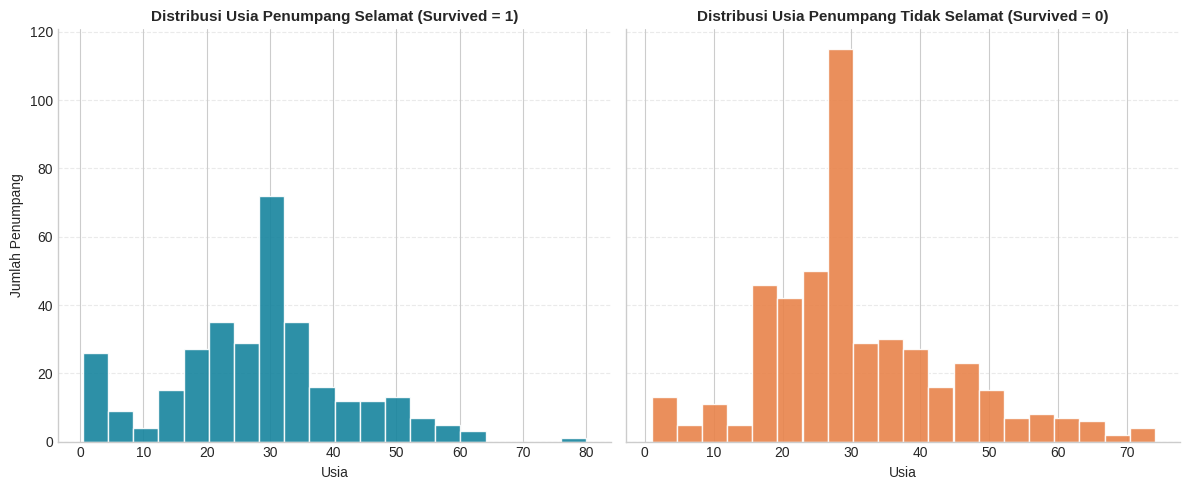

In [9]:
# Memisahkan data penumpang selamat dan tidak selamat
survived_passengers = df[df["survived"] == 1]
not_survived_passengers = df[df["survived"] == 0]

# Membuat subplots 1x2
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Histogram untuk penumpang Selamat
axes[0].hist(survived_passengers["age"].dropna(), bins=20, color="#16849E", edgecolor="white", alpha=0.9)
axes[0].set_title("Distribusi Usia Penumpang Selamat (Survived = 1)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Usia")
axes[0].set_ylabel("Jumlah Penumpang")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

# Histogram untuk penumpang Tidak Selamat
axes[1].hist(not_survived_passengers["age"].dropna(), bins=20, color="#E8834A", edgecolor="white", alpha=0.9)
axes[1].set_title("Distribusi Usia Penumpang Tidak Selamat (Survived = 0)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Usia")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

Latihan 3

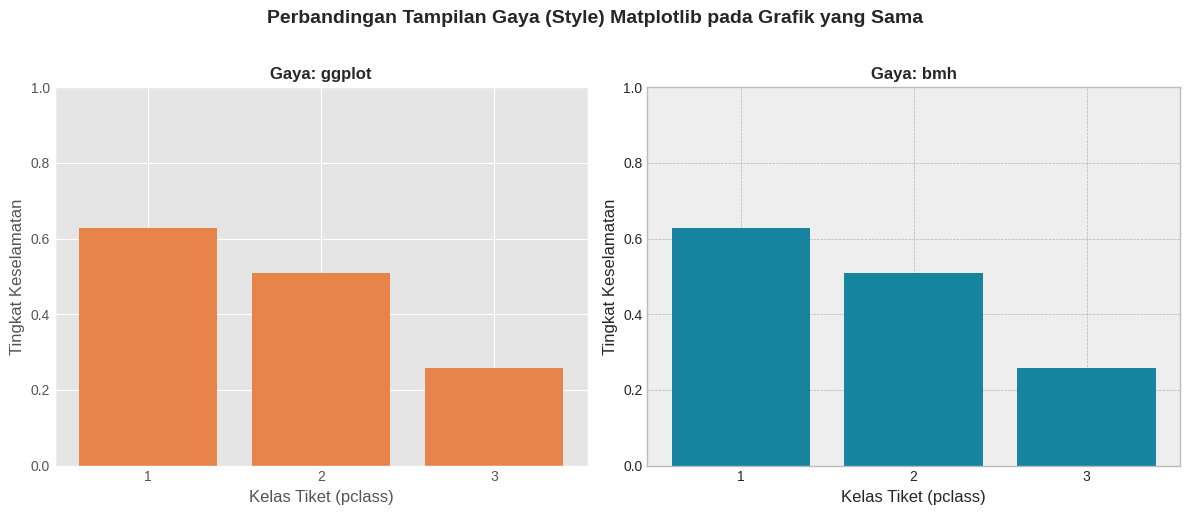

In [10]:
# Menghitung data tingkat keselamatan per pclass untuk visualisasi
tingkat_pclass = df.groupby("pclass")["survived"].mean()

# Membuat figure dengan ukuran yang sesuai
fig = plt.figure(figsize=(12, 5))

# Menggunakan context manager 'ggplot' untuk subplot pertama
with plt.style.context("ggplot"):
    ax1 = fig.add_subplot(1, 2, 1)
    ax1.bar(tingkat_pclass.index.astype(str), tingkat_pclass.values, color="#E8834A")
    ax1.set_title("Gaya: ggplot", fontsize=12, fontweight="bold")
    ax1.set_xlabel("Kelas Tiket (pclass)")
    ax1.set_ylabel("Tingkat Keselamatan")
    ax1.set_ylim(0, 1.0)

# Menggunakan context manager 'bmh' untuk subplot kedua
with plt.style.context("bmh"):
    ax2 = fig.add_subplot(1, 2, 2)
    ax2.bar(tingkat_pclass.index.astype(str), tingkat_pclass.values, color="#16849E")
    ax2.set_title("Gaya: bmh", fontsize=12, fontweight="bold")
    ax2.set_xlabel("Kelas Tiket (pclass)")
    ax2.set_ylabel("Tingkat Keselamatan")
    ax2.set_ylim(0, 1.0)

plt.suptitle("Perbandingan Tampilan Gaya (Style) Matplotlib pada Grafik yang Sama", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

Latihan 4

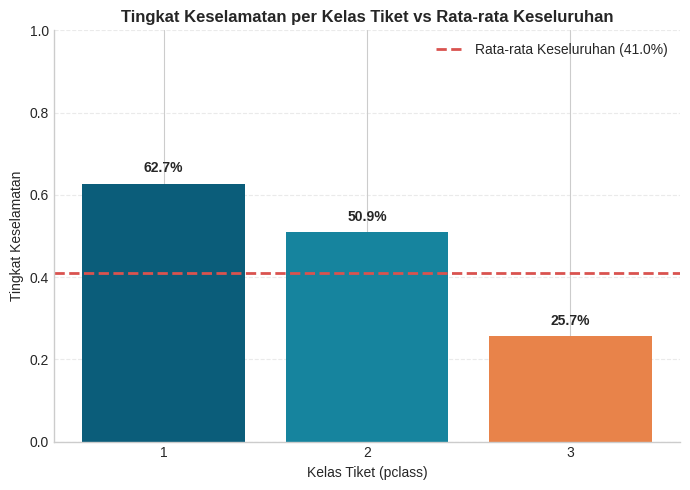

In [11]:
# Menghitung tingkat keselamatan per kelas tiket (pclass)
tingkat_pclass = df.groupby("pclass")["survived"].mean()

# Menghitung rata-rata keseluruhan tingkat keselamatan
rata_rata_keseluruhan = df["survived"].mean()

fig, ax = plt.subplots(figsize=(7, 5))

# Membuat bar chart
bars = ax.bar(tingkat_pclass.index.astype(str), tingkat_pclass.values, color=["#0B5D7A", "#16849E", "#E8834A"])

# Menambahkan garis rata-rata keseluruhan
ax.axhline(rata_rata_keseluruhan, color="#D9534F", linestyle="--", linewidth=2,
           label=f"Rata-rata Keseluruhan ({rata_rata_keseluruhan:.1%})")

# Menambahkan label persentase di atas setiap bar
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.02,
            f"{height:.1%}", ha="center", va="bottom", fontweight="bold")

# Mengatur judul, label, dan batas y
ax.set_title("Tingkat Keselamatan per Kelas Tiket vs Rata-rata Keseluruhan", fontsize=12, fontweight="bold")
ax.set_xlabel("Kelas Tiket (pclass)")
ax.set_ylabel("Tingkat Keselamatan")
ax.set_ylim(0, 1.0)

# Menampilkan legenda
ax.legend(loc="upper right")

# Menyempurnakan grid dan tampilan garis batas
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

Latihan 5

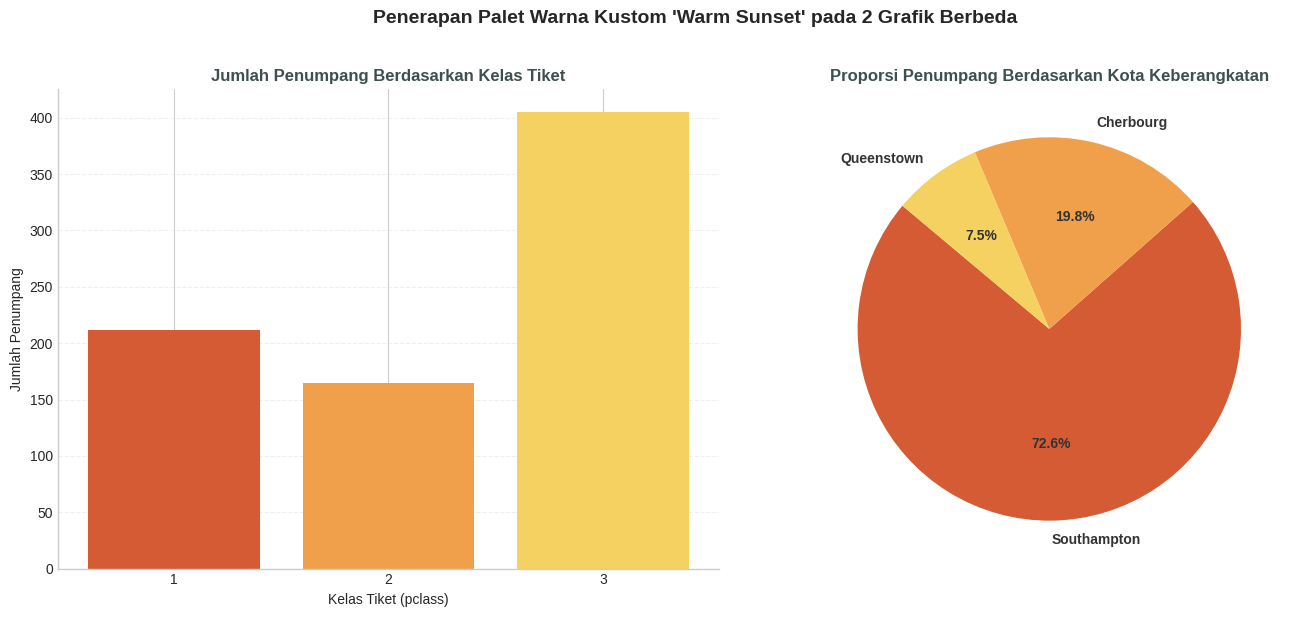

In [12]:
# Menentukan palet warna kustom bertema "Warm Sunset"
senja_palette = ["#D45B34", "#F0A04B", "#F4D160", "#3F4E4F"]

# Menghitung data untuk grafik pertama (Jumlah Penumpang per Kelas Tiket)
jumlah_kelas = df["pclass"].value_counts().sort_index()

# Menghitung data untuk grafik kedua (Proporsi Kota Keberangkatan)
proporsi_embark = df["embark_town"].value_counts()

# Membuat Grid Subplot 1x2 untuk membandingkan kedua grafik secara berdampingan
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# GRAFIK 1: Bar Chart (Jumlah Penumpang berdasarkan Kelas)
axes[0].bar(jumlah_kelas.index.astype(str), jumlah_kelas.values, color=senja_palette[:3], edgecolor="none")
axes[0].set_title("Jumlah Penumpang Berdasarkan Kelas Tiket", fontsize=12, fontweight="bold", color="#3F4E4F")
axes[0].set_xlabel("Kelas Tiket (pclass)", fontsize=10)
axes[0].set_ylabel("Jumlah Penumpang", fontsize=10)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

# GRAFIK 2: Pie Chart (Proporsi Pelabuhan Keberangkatan)
axes[1].pie(proporsi_embark.values, labels=proporsi_embark.index, autopct="%1.1f%%",
            startangle=140, colors=senja_palette, textprops={'fontweight': 'bold', 'color': '#333333'})
axes[1].set_title("Proporsi Penumpang Berdasarkan Kota Keberangkatan", fontsize=12, fontweight="bold", color="#3F4E4F")

plt.suptitle("Penerapan Palet Warna Kustom 'Warm Sunset' pada 2 Grafik Berbeda", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Pertanyaan Diskusi

### Jawaban Pertanyaan Diskusi

**1. Elemen Kustomisasi yang Paling Berpengaruh Terhadap Kemudahan Membaca Grafik**

Menurut saya, elemen kustomisasi yang memiliki pengaruh paling besar adalah **anotasi nilai (label data langsung)** dan **judul yang informatif**, yang didukung kuat oleh **pemilihan warna yang fungsional**.
* **Judul yang informatif** memberikan konteks instan mengenai apa yang sedang dibahas oleh grafik tersebut tanpa membuat pembaca harus menebak tujuan utamanya.
* **Anotasi/label data langsung** (seperti menampilkan persentase `73.9%` tepat di atas batang) sangat mempermudah pembaca dalam menangkap nilai presisi dari data secara cepat. Pembaca tidak perlu lagi menarik garis khayal secara manual dari puncak batang ke arah sumbu Y (proses pencocokan visual sumbu) yang sering kali melelahkan dan kurang akurat.
* **Warna yang kontras dan fungsional** membantu mengarahkan fokus mata pembaca secara langsung ke kategori atau perbandingan yang paling krusial sebelum mereka membaca teks penjelas lainnya.


**2. Masukan Peer Review yang Paling Bermanfaat**

Berdasarkan catatan peer review dari, masukan yang paling bermanfaat adalah konfirmasi objektif bahwa seluruh grafik di dalam notebook telah memenuhi standar kelayakan visualisasi data (semua grafik memiliki judul yang jelas, sumbu X dan Y informatif, dilengkapi legenda untuk multi-kategori, serta kontras warna yang mudah dibedakan).

Masukan tersebut sangat bermanfaat karena memvalidasi bahwa pendekatan penyempurnaan grafik yang diterapkan—seperti penggunaan palet warna kustom yang kontras, penambahan anotasi data, penghilangan garis batas (*spines*) atas dan kanan, serta penataan *grid* tipis—telah berhasil membuat informasi lebih mudah diakses dan dipahami secara profesional tanpa adanya kendala teknis (bebas dari error *runtime*).


**3. Risiko Desain Grafik yang Terlalu "Ramai"**

Apabila sebuah grafik didesain terlalu ramai dengan elemen dekoratif, warna yang berlebihan, dan anotasi yang terlalu padat, terdapat beberapa risiko utama yang akan merugikan efektivitas penyampaian informasi, di antaranya:
* **Beban Kognitif yang Tinggi (Cognitive Overload):** Pembaca akan kesulitan menemukan poin pesan utama yang ingin disampaikan karena perhatian mereka terdistraksi oleh terlalu banyak rangsangan visual yang tidak perlu.
* **Ilusi dan Distorsi Data:** Penggunaan terlalu banyak warna yang tidak memiliki arti fungsional dapat membingungkan pembaca, di mana mereka mungkin mencoba mencari hubungan logis dari kesamaan warna dekoratif yang sebenarnya tidak memiliki korelasi data.
* **Kehilangan Estetika Profesional (Clutter):** Grafik yang terlalu ramai justru akan terlihat berantakan, tidak terstruktur, dan kurang kredibel secara ilmiah maupun profesional, sehingga esensi utama dari komunikasi visual data menjadi gagal tersampaikan.